# FalkorDB proof of concept: query local EdU clustering

**Question:** If two simulated lobes contain the same Dpn-like cell positions and the same number of EdU positive cells, can a graph query detect which one has EdU positive cells concentrated near one another?

This follows the question in `vistiq_pyg_spatial_poc.ipynb`, but tests a **graph database** rather than a graph neural network. FalkorDB stores cells, lobes, and their relationships, then answers Cypher queries. It does **not** learn a prediction model in this notebook.

All data here are **synthetic**. “Dpn-like” and “EdU positive” are simulated labels inspired by the Vistiq project; these are not measured cells, images, experimental conclusions, or validated biological observations. No `.lif` file, Vistiq analysis bundle, GPU, or PyTorch installation is needed.

**Model:** `(:Lobe)-[:CONTAINS]->(:Cell)-[:NEAR]->(:Cell)`. Each cell has coordinates, simulated volume and Dpn intensity, and `edu` equal to 0 or 1. `NEAR` is a directed link to one of the cell's *k* closest neighbors in Euclidean 3D coordinates. A cell may have an outgoing link to another cell even if the reverse link does not exist. Every `NEAR` edge stays inside its lobe.

Run top to bottom after starting the FalkorDB server in Section 0. On UVA HPC, the notebook connects to a server on the same compute node; the synthetic data live in memory and are not saved to disk.

## 0. Start FalkorDB on UVA HPC

Request an OOD **JupyterLab CPU job** (1–2 cores, about 8 GB RAM, 1–2 hours). Use the **Python (Vistiq POC)** kernel pointing at `~/vistiqlab/vistiq/.venv`. In a **JupyterLab Terminal in that same job**, download the FalkorDB container once:

```bash
module load apptainer
mkdir -p ~/vistiqlab
apptainer pull ~/vistiqlab/falkordb-server.sif \
  docker://falkordb/falkordb-server:v4.20.6-x64
```

For each new JupyterLab session, start the server in a terminal **on the same compute node as the notebook**:

```bash
module load apptainer
apptainer exec --cleanenv ~/vistiqlab/falkordb-server.sif \
  redis-server \
  --port 16379 \
  --bind 127.0.0.1 \
  --protected-mode yes \
  --save '' \
  --appendonly no \
  --dir /tmp \
  --loadmodule /var/lib/falkordb/bin/falkordb.so
```

**Keep that terminal running** while you execute the notebook. The next cell uses the `falkordb` Python client to connect to `127.0.0.1:16379`; install `falkordb` in the selected kernel if the import fails. The address `127.0.0.1` reaches only the same compute node, so a terminal on a login node or in another OOD job will not connect. You do not need a GPU. Stop the server with Ctrl+C when done. With `--save ''` and `--appendonly no`, these database results are temporary.

The embedded `falkordblite` backend remains available by setting `BACKEND = "embedded"` in the next cell **on a compatible machine**. On the UVA node we checked, glibc 2.28 cannot load its `falkordb.so`, which requires newer glibc and OpenSSL libraries. The container server above worked instead. If using another authorized server, set `FALKORDB_HOST`, `FALKORDB_PORT`, and optionally `FALKORDB_PASSWORD` in the Jupyter process environment before connecting. Do not expose an unauthenticated server to a public network.


In [1]:
import os
import sys
import tempfile
from pathlib import Path
from uuid import uuid4

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BACKEND = "server"  # Change to "server" only if you have a FalkorDB instance.
os.environ["FALKORDB_PORT"] = "16379"

print("Kernel Python:", sys.executable)
print("Backend:", BACKEND)
print("NumPy:", np.__version__)

if BACKEND == "embedded":
    try:
        from redislite.falkordb_client import FalkorDB
    except ImportError as exc:
        raise ImportError(
            "Install falkordblite into the Python executable printed above, "
            "then restart this kernel. See the setup instructions below."
        ) from exc
    temporary_db = tempfile.TemporaryDirectory(prefix="vistiq-falkordb-")
    try:
        db = FalkorDB(str(Path(temporary_db.name) / "poc.db"))
    except Exception as exc:
        raise RuntimeError(
            "FalkorDBLite could not start. Check your node's glibc and the "
            "underlying error; if incompatible, use a suitable machine or "
            "choose BACKEND='server' with an available FalkorDB server."
        ) from exc
elif BACKEND == "server":
    from falkordb import FalkorDB

    db = FalkorDB(
        host=os.environ.get("FALKORDB_HOST", "127.0.0.1"),
        port=int(os.environ.get("FALKORDB_PORT", "6379")),
        password=os.environ.get("FALKORDB_PASSWORD") or None,
    )
else:
    raise ValueError("BACKEND must be 'embedded' or 'server'")

# A unique name prevents overwriting another experiment on a shared server.
graph_name = "vistiq_spatial_poc_" + uuid4().hex[:12]
graph = db.select_graph(graph_name)
print("Graph name:", graph_name)

Kernel Python: /sfs/gpfs/tardis/home/tqv9uu/vistiqlab/vistiq/.venv/bin/python
Backend: server
NumPy: 2.5.4
Graph name: vistiq_spatial_poc_0ad7a5dbf2bb


## 1. Simulate matched lobes

Each pair reuses **exactly the same** cell positions, volumes, Dpn intensity values, nearest neighbor links, and number of EdU positive cells. In the *scattered* version, the positive cells are chosen at random. In the *clustered* version, most positives lie close to a randomly selected anchor. The label describes the way **this synthetic dataset** was generated; it is not a diagnosis or prediction for an individual cell.

We use 12 pairs (24 lobes) and 60 cells per lobe, with 18 positive cells. More pairs help check the result across repeated simulations, but they also create more database nodes and edges. Coordinates can be thought of as made-up micrometre positions.

In [2]:
SEED = 42
N_PAIRS = 12
N_CELLS = 60
N_EDU = 18
K = 5
rng = np.random.default_rng(SEED)


def simulate_pair(pair_id, rng):
    xyz = rng.uniform([0, 0, 0], [80, 80, 22], size=(N_CELLS, 3))
    volume = rng.lognormal(mean=2.9, sigma=0.25, size=N_CELLS)
    dpn_intensity = rng.lognormal(mean=2.3, sigma=0.22, size=N_CELLS)

    delta = xyz[:, None, :] - xyz[None, :, :]
    distance = np.sqrt(np.sum(delta**2, axis=-1))
    np.fill_diagonal(distance, np.inf)  # A cell cannot be its own neighbor.
    nearest = np.argsort(distance, axis=1)[:, :K]

    scattered = np.zeros(N_CELLS, dtype=int)
    scattered[rng.choice(N_CELLS, size=N_EDU, replace=False)] = 1

    anchor = int(rng.integers(N_CELLS))
    # Choose many positive cells near the same anchor, then a few elsewhere.
    core_count = int(round(0.78 * N_EDU))
    core = np.argsort(np.linalg.norm(xyz - xyz[anchor], axis=1))[:core_count]
    remaining = np.setdiff1d(np.arange(N_CELLS), core)
    others = rng.choice(remaining, size=N_EDU - core_count, replace=False)
    clustered = np.zeros(N_CELLS, dtype=int)
    clustered[np.concatenate([core, others])] = 1

    return {
        "pair_id": pair_id,
        "xyz": xyz,
        "volume": volume,
        "dpn_intensity": dpn_intensity,
        "distance": distance,
        "nearest": nearest,
        "edu": {"scattered": scattered, "clustered": clustered},
    }


pairs = [simulate_pair(i, rng) for i in range(N_PAIRS)]
first = pairs[0]
assert all(int(e.sum()) == N_EDU for p in pairs for e in p["edu"].values())
print(f"{N_PAIRS} matched pairs, {2*N_PAIRS*N_CELLS} cell nodes, "
      f"{2*N_PAIRS*N_CELLS*K} directed NEAR relationships")
print("First pair's EdU counts:", {name: int(e.sum()) for name, e in first["edu"].items()})

12 matched pairs, 1440 cell nodes, 7200 directed NEAR relationships
First pair's EdU counts: {'scattered': 18, 'clustered': 18}


## 2. Look at a matched pair

The plots show x and y for simplicity. The nearest neighbor computation above still uses x, y **and z**. The background cloud and cell measurements are identical across the two panels; the color assignment changes.

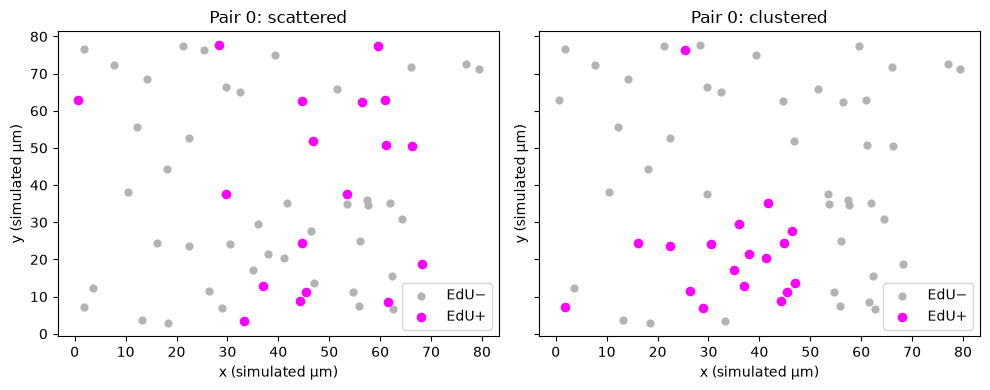

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, condition in zip(axes, ("scattered", "clustered")):
    xyz = first["xyz"]
    edu = first["edu"][condition]
    ax.scatter(xyz[edu == 0, 0], xyz[edu == 0, 1], s=24, c="0.7", label="EdU−")
    ax.scatter(xyz[edu == 1, 0], xyz[edu == 1, 1], s=35, c="magenta", label="EdU+")
    ax.set(title=f"Pair 0: {condition}", xlabel="x (simulated µm)", ylabel="y (simulated µm)")
    ax.legend()
plt.tight_layout()
plt.show()

## 3. Convert the arrays into a property graph

Each `Lobe` node has a `pair_id`, a `condition`, and a unique `id`. Each `Cell` node has a unique `id`, its simulated measurements, and `edu` (0 or 1). A `CONTAINS` edge links a lobe to each of its cells. Each `NEAR` edge goes from a cell to one of its five nearest cells in that lobe and records their 3D distance.

We insert rows in batches with parameterized Cypher `UNWIND`. An index on `Cell.id` makes later endpoint lookups faster. Data generation and k-nearest-neighbor calculations happen in NumPy; FalkorDB stores the resulting graph and performs relationship queries. The two tools have different roles.

In [4]:
lobes, cells, edges = [], [], []
edge_arrays = {}  # Used later for an independent NumPy check.
for p in pairs:
    pair_id = p["pair_id"]
    for condition, edu in p["edu"].items():
        lobe_id = f"pair_{pair_id:03d}_{condition}"
        lobes.append({"id": lobe_id, "pair_id": pair_id, "condition": condition})
        source_indices = np.repeat(np.arange(N_CELLS), K)
        target_indices = p["nearest"].reshape(-1)
        edge_arrays[lobe_id] = (source_indices, target_indices)
        for i in range(N_CELLS):
            cells.append({
                "id": f"{lobe_id}_cell_{i:03d}", "lobe_id": lobe_id,
                "edu": int(edu[i]),
                "x": float(p["xyz"][i, 0]),
                "y": float(p["xyz"][i, 1]),
                "z": float(p["xyz"][i, 2]),
                "volume": float(p["volume"][i]),
                "dpn_intensity": float(p["dpn_intensity"][i]),
            })
        for src, dst in zip(source_indices, target_indices):
            edges.append({
                "src": f"{lobe_id}_cell_{src:03d}",
                "dst": f"{lobe_id}_cell_{dst:03d}",
                "distance": float(p["distance"][src, dst]),
            })


def batches(rows, size=250):
    for start in range(0, len(rows), size):
        yield rows[start:start + size]


graph.query("CREATE INDEX FOR (c:Cell) ON (c.id)")
graph.query("CREATE INDEX FOR (l:Lobe) ON (l.id)")
graph.query("""
    UNWIND $rows AS row
    CREATE (:Lobe {id: row.id, pair_id: row.pair_id, condition: row.condition})
""", params={"rows": lobes})

for rows in batches(cells):
    graph.query("""
        UNWIND $rows AS row
        MATCH (l:Lobe {id: row.lobe_id})
        CREATE (c:Cell {
            id: row.id, edu: row.edu,
            x: row.x, y: row.y, z: row.z,
            volume: row.volume, dpn_intensity: row.dpn_intensity
        })
        CREATE (l)-[:CONTAINS]->(c)
    """, params={"rows": rows})

for rows in batches(edges):
    graph.query("""
        UNWIND $rows AS row
        MATCH (a:Cell {id: row.src})
        MATCH (b:Cell {id: row.dst})
        CREATE (a)-[:NEAR {distance: row.distance}]->(b)
    """, params={"rows": rows})

print("Inserted", len(lobes), "lobes,", len(cells), "cells, and", len(edges), "NEAR edges")

Inserted 24 lobes, 1440 cells, and 7200 NEAR edges


## 4. Verify what went into the database

`MATCH` selects graph patterns; `count` and `sum` summarize the rows. These checks catch partial insertions before we interpret a score. A failed assertion means the database contents differ from the simulated arrays.

In [5]:
n_lobes = graph.ro_query("MATCH (l:Lobe) RETURN count(l)").result_set[0][0]
n_cells = graph.ro_query("MATCH (c:Cell) RETURN count(c)").result_set[0][0]
n_near = graph.ro_query("MATCH (:Cell)-[r:NEAR]->(:Cell) RETURN count(r)").result_set[0][0]
n_contains = graph.ro_query("MATCH (:Lobe)-[r:CONTAINS]->(:Cell) RETURN count(r)").result_set[0][0]
print({"lobes": n_lobes, "cells": n_cells, "CONTAINS": n_contains, "NEAR": n_near})
assert n_lobes == len(lobes)
assert n_cells == n_contains == len(cells)
assert n_near == len(edges)

{'lobes': 24, 'cells': 1440, 'CONTAINS': 1440, 'NEAR': 7200}


## 5. Ask a relationship question in Cypher

For every directed nearest neighbor link `a → b`, ask whether **both** cells are EdU positive. We define

$$S_\ell = \frac{\#\{(a,b) \in E_\ell:\; a.\mathrm{edu}=1 \land b.\mathrm{edu}=1\}}{\#\{(a,b) \in E_\ell:\; a.\mathrm{edu}=1\}}.$$

Here $E_\ell$ is the set of directed `NEAR` edges inside lobe $\ell$. The denominator is $k$ times the number of EdU positive source cells (here $5\times18$). The score estimates the fraction of neighbor **slots from positive source cells** that end at positive cells. It is **not** a probability output by a trained model. Higher values indicate that EdU positive cells tend to have EdU positive neighbors.

The `CONTAINS` pattern joins a `Lobe` to its source cells; the `NEAR` pattern follows each source to a target. `CASE` counts only edges meeting the condition. Grouping by lobe returns one row per simulated lobe.

In [6]:
score_query = """
MATCH (l:Lobe)-[:CONTAINS]->(a:Cell)-[:NEAR]->(b:Cell)
RETURN l.id AS lobe_id, l.pair_id AS pair_id, l.condition AS condition,
       sum(CASE WHEN a.edu = 1 AND b.edu = 1 THEN 1 ELSE 0 END) AS positive_to_positive,
       sum(CASE WHEN a.edu = 1 THEN 1 ELSE 0 END) AS positive_source_slots
ORDER BY pair_id, condition
"""
rows = graph.ro_query(score_query).result_set
scores = pd.DataFrame(rows, columns=[
    "lobe_id", "pair_id", "condition", "positive_to_positive", "positive_source_slots"
])
scores["neighbor_score"] = scores["positive_to_positive"] / scores["positive_source_slots"]
assert len(scores) == 2 * N_PAIRS
assert (scores["positive_source_slots"] == K * N_EDU).all()
display(scores.head(8))

,lobe_id,pair_id,condition,positive_to_positive,positive_source_slots,neighbor_score
0,pair_000_clustered,0,clustered,65.0,90.0,0.722222
1,pair_000_scattered,0,scattered,31.0,90.0,0.344444
2,pair_001_clustered,1,clustered,52.0,90.0,0.577778
3,pair_001_scattered,1,scattered,37.0,90.0,0.411111
4,pair_002_clustered,2,clustered,58.0,90.0,0.644444
5,pair_002_scattered,2,scattered,29.0,90.0,0.322222
6,pair_003_clustered,3,clustered,62.0,90.0,0.688889
7,pair_003_scattered,3,scattered,30.0,90.0,0.333333


## 6. Compare a global summary with the graph query

A global EdU fraction ignores spatial location. Because the pairs are matched, it is exactly $18/60=0.30$ in *both* conditions. A global fraction cannot rank the two lobes in any pair. The neighbor score can sometimes rank them because it uses spatial links.

The comparison below uses **no training, model fitting, train/test split, or learned threshold**: it simply asks which of each matched pair has a higher positive-neighbor score. If the scores tie, the result is a tie rather than an invented correct prediction.

In [7]:
global_query = """
MATCH (l:Lobe)-[:CONTAINS]->(c:Cell)
RETURN l.id AS lobe_id, count(c) AS n_cells, sum(c.edu) AS n_edu
"""
global_rows = graph.ro_query(global_query).result_set
globals_df = pd.DataFrame(global_rows, columns=["lobe_id", "n_cells", "n_edu"])
globals_df["global_fraction"] = globals_df["n_edu"] / globals_df["n_cells"]
assert len(globals_df) == 2 * N_PAIRS
assert (globals_df["n_cells"] == N_CELLS).all()
assert (globals_df["n_edu"] == N_EDU).all()

comparison = scores.merge(globals_df, on="lobe_id")
wide = comparison.pivot(index="pair_id", columns="condition", values="neighbor_score")
wide["difference"] = wide["clustered"] - wide["scattered"]
wins = int((wide["difference"] > 0).sum())
ties = int((wide["difference"] == 0).sum())
print("Unique global fractions:", sorted(comparison["global_fraction"].unique()))
print(f"Higher clustered score: {wins}/{N_PAIRS} matched pairs; ties: {ties}")
display(wide.round(3))

Unique global fractions: [np.float64(0.3)]
Higher clustered score: 12/12 matched pairs; ties: 0


condition,clustered,scattered,difference
pair_id,,,
0,0.722,0.344,0.378
1,0.578,0.411,0.167
2,0.644,0.322,0.322
3,0.689,0.333,0.356
4,0.633,0.289,0.344
5,0.589,0.322,0.267
6,0.678,0.256,0.422
7,0.700,0.300,0.400
8,0.667,0.289,0.378


## 7. Inspect actual neighboring cells

This query returns a few individual `NEAR` relationships for the clustered version of pair 0. It illustrates what a graph database can give a researcher beyond one number: **which** cells are connected, their positive status, and their distance. Run it again with another `lobe_id` to explore a different simulated lobe.

In [8]:
example_lobe = "pair_000_clustered"
neighbors = graph.ro_query("""
    MATCH (l:Lobe {id: $lobe_id})-[:CONTAINS]->(a:Cell)-[r:NEAR]->(b:Cell)
    WHERE a.edu = 1
    RETURN a.id AS source, b.id AS neighbor, a.edu AS source_edu,
           b.edu AS neighbor_edu, r.distance AS distance
    ORDER BY source, distance
    LIMIT 12
""", params={"lobe_id": example_lobe}).result_set
display(pd.DataFrame(neighbors, columns=[
    "source", "neighbor", "source_edu", "neighbor_edu", "distance"
]).round({"distance": 2}))

,source,neighbor,source_edu,neighbor_edu,distance
0,pair_000_clustered_cell_003,pair_000_clustered_cell_031,1,1,10.20
1,pair_000_clustered_cell_003,pair_000_clustered_cell_057,1,1,10.55
2,pair_000_clustered_cell_003,pair_000_clustered_cell_044,1,1,12.94
3,pair_000_clustered_cell_003,pair_000_clustered_cell_048,1,1,15.62
4,pair_000_clustered_cell_003,pair_000_clustered_cell_025,1,1,15.97
5,pair_000_clustered_cell_019,pair_000_clustered_cell_016,1,0,9.29
6,pair_000_clustered_cell_019,pair_000_clustered_cell_029,1,1,12.18
7,pair_000_clustered_cell_019,pair_000_clustered_cell_051,1,1,12.58
8,pair_000_clustered_cell_019,pair_000_clustered_cell_022,1,1,13.28
9,pair_000_clustered_cell_019,pair_000_clustered_cell_048,1,1,13.58


## 8. Cross-check the database result independently

Use the original NumPy neighbor indices to recompute the same directed-edge score. Equality means that Cypher retrieval and the stored graph structure agree with the generator. This is a data-integrity check, not independent biological validation.

In [9]:
for p in pairs:
    for condition, edu in p["edu"].items():
        lobe_id = f"pair_{p['pair_id']:03d}_{condition}"
        src, dst = edge_arrays[lobe_id]
        numerator = int(((edu[src] == 1) & (edu[dst] == 1)).sum())
        denominator = int((edu[src] == 1).sum())
        db_row = scores.loc[scores["lobe_id"] == lobe_id].iloc[0]
        assert numerator == db_row["positive_to_positive"]
        assert denominator == db_row["positive_source_slots"]
print("All", 2 * N_PAIRS, "FalkorDB scores match direct NumPy counts.")

All 24 FalkorDB scores match direct NumPy counts.


## 9. Interpretation and next experiment

- `CONTAINS` and `NEAR` answer different questions: membership in a lobe versus spatial proximity between cells. Neither link is the IoU/IoS segmentation-overlap metric from `analyze-graph.ipynb`.
- The global EdU fraction is identical in each pair by design. If the clustered lobes usually have larger neighbor scores, the example demonstrates how a graph query can recover spatial information that a global count loses.
- The score is a deliberately chosen hand-built statistic, and the clustered pattern was deliberately built into the simulation. This is **not evidence** that FalkorDB learns a classifier, outperforms PyTorch Geometric, or has predictive value on animal images. The query and results can feed a downstream analysis or a GNN, but the database itself does not train one.
- On real data, define what each cell node represents, use physical pixel sizes when computing neighbors, handle segmentation and marker uncertainty, and evaluate on separate animals rather than cells drawn from one image.

**Optional cleanup:** when you are finished inspecting the result, execute the next cell to delete *only this notebook's uniquely named graph*. For the embedded backend, the temporary folder also goes away when the kernel exits.

In [10]:
# Uncomment only after you finish exploring; this deletes this run's graph.
# graph.delete()
# print("Deleted:", graph_name)